# Métricas e treinamento · XGBoost

GridSearchCV reproduzível, baseline e diagnósticos de **treino e validação**.
**TEST não é avaliado neste notebook.** Os gráficos leem artefatos persistidos;
abrir ou executar o notebook com a configuração padrão não repete a busca.

## 1. Protocolo e origem das métricas

- Alvo Machine failure; classe positiva 1. Cinco sensores e Type, sem IDs ou modos de falha.
- Mesma reserva da EDA: FIT 6.400, validação posterior 1.600 e TEST reservado 2.000.
- Três folds de prefixos crescentes em FIT. Sem shuffle ou gap; UDI não é data real.
- Critério: maior média de **AUPRC trapezoidal entre candidatos com SMOTENC**. Desempate usa primeiro candidato.
- Elegíveis: SMOTENC e SMOTENC + pesos. Controles sem balanceamento e só pesos não podem vencer o refit.
- Imputação e padronização numérica, SMOTENC dentro dos treinos e one-hot depois da síntese.
- Todos os braços usam o mesmo pré-processamento; sampler desligado nos controles.
- A validação conserva seus registros e prevalência. Sem reamostragem na inferência.
- Refit somente em FIT de 6.400. Limiar fixo score >= 0,5; métricas de área usam predict_proba[:, 1].
- AP e AUPRC trapezoidal são métricas distintas. A CV do escolhido tem otimismo de seleção.
- Validação já usada no desenvolvimento; não é confirmação independente. TEST não é avaliado.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'configs/training.json').is_file() and (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from predictive_maintenance.training import run_experiment, latest_run
from predictive_maintenance.reporting import ModelReport
from predictive_maintenance.presentation import readable_table, readable_parameters, translate_text

def translated_markdown(text):
    return Markdown(translate_text(text))

from predictive_maintenance.data import sha256

MODEL_NAME = 'xgboost'
RUN_TRAINING = False  # True executa uma nova busca e preserva as anteriores.
RUN_ID = None  # Informe um ID salvo para revisar exatamente aquela execução.
if RUN_TRAINING:
    run = run_experiment(ROOT, MODEL_NAME)
elif RUN_ID:
    run = ROOT / 'reports/experiments' / RUN_ID
else:
    run = latest_run(ROOT, MODEL_NAME)
report = ModelReport(ROOT, run)
manifest = report.manifest
if manifest['model'] != MODEL_NAME:
    raise ValueError('Execução pertence a outro modelo.')
print('Execução:', manifest['run_id'])
print('Dataset SHA256:', manifest['dataset_sha256'])
print('CSV atual corresponde:', sha256(ROOT / manifest['data_config']['source']) == manifest['dataset_sha256'])
print('TEST avaliado:', manifest['test_evaluated'])
display(manifest['versions'])

Execução: train_xgboost_20261031T235601Z_fa7abc82
Dataset SHA256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
CSV atual corresponde: True
TEST avaliado: False


{'scikit-learn': '1.9.1',
 'xgboost': '3.4.1',
 'pandas': '2.3.3',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'joblib': '1.6.0',
 'imbalanced-learn': '0.14.2'}

## 2. Grade condicional, custo e melhores parâmetros

72 candidatos × 3 folds = 216 ajustes de busca, mais 1 refit por modelo.
São 8 controles sem balanceamento, 16 só pesos, 16 SMOTENC e 32 SMOTENC + pesos.
Há ainda baseline e três diagnósticos por tamanho com parâmetros congelados.

150 árvores ficam **fixas** nesta rodada para concentrar orçamento no balanceamento.
A grade base tem 8 configurações. Pesos positivos 3 e 10, razões de síntese 0,25 e 0,5,
e k_neighbors=3 fixo (45 falhas no menor treino da CV).

`scale_pos_weight` dá peso maior à falha: XGBoost usa multiplicadores 3/10;
Random Forest usa dicionários {0: 1, 1: 3} / {0: 1, 1: 10}.
SMOTENC sozinho usa peso neutro. A combinação é comparada, sem presumir que vence.

`mean_test_*` significa validação dos folds em FIT, não o TEST reservado.
Grade condicional completa, incluindo controles e parâmetros, está no manifesto e abaixo.

Os quatro braços usam os mesmos hiperparâmetros base. Razões de síntese significam falhas/não falhas após a operação, não a fração da minoria no total. A padronização serve às distâncias do sampler. Pesos explícitos evitam o recálculo automático de balanced sobre dados já reamostrados. Critério Gini/bootstrap no RF e subsampling/regularização no XGBoost ficam fixos. Não há early stopping, undersampling ou ajuste de limiar.

**Grade condicional completa:**

Bloco 1

Parâmetro,Descrição,Valor
model__max_depth,Profundidade máxima,"[2, 4]"
model__learning_rate,Taxa de aprendizado,"[0.05, 0.15]"
model__min_child_weight,Peso mínimo de filho,"[1, 5]"
sampler,sampler,['passthrough']
model__scale_pos_weight,Peso da classe positiva,[1]


Bloco 2

Parâmetro,Descrição,Valor
model__max_depth,Profundidade máxima,"[2, 4]"
model__learning_rate,Taxa de aprendizado,"[0.05, 0.15]"
model__min_child_weight,Peso mínimo de filho,"[1, 5]"
sampler,sampler,['passthrough']
model__scale_pos_weight,Peso da classe positiva,"[3, 10]"


Bloco 3

... (6 outputs left out)

**Melhores parâmetros na grade:**

Parâmetro,Descrição,Valor
model__learning_rate,Taxa de aprendizado,0.05
model__max_depth,Profundidade máxima,2
model__min_child_weight,Peso mínimo de filho,5
model__scale_pos_weight,Peso da classe positiva,1
sampler,sampler,SMOTENC
sampler__sampling_strategy,Razão de falhas/não falhas após SMOTENC,0.25


AUPRC média de seleção: 0.5353
Tempo da busca: 118.0 s


,AUPRC trapezoidal (score) — posição — validação CV,AUPRC trapezoidal (score) — média — validação CV,AUPRC trapezoidal (score) — desvio — validação CV,AUPRC trapezoidal (score) — média — treino CV,AP (score) — média — validação CV,F1 (%) — média — validação CV,Recall (%) — média — validação CV,Precision (%) — média — validação CV,Tempo médio de ajuste (s),Parâmetros
26,1,"0,5353","0,0686","0,8259","0,5357","40,25%","59,15%","43,72%","0,7737","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 5, ""model__scale_pos_weight"": 1, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
24,2,"0,5335","0,0718","0,8320","0,5339","39,55%","58,16%","42,83%","0,7847","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 1, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
48,3,"0,5305","0,0849","0,9645","0,5331","38,33%","60,44%","42,14%","0,9368","{""model__learning_rate"": 0.05, ""model__max_depth"": 4, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 3, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
44,4,"0,5220","0,0712","0,7971","0,5221","32,68%","68,56%","25,14%","0,7872","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 5, ""model__scale_pos_weight"": 3, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
32,5,"0,5198","0,0693","0,9118","0,5224","36,54%","52,88%","45,05%","0,7707","{""model__learning_rate"": 0.15, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 1, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
28,6,"0,5181","0,0824","0,9578","0,5207","41,43%","54,91%","49,48%","0,8796","{""model__learning_rate"": 0.05, ""model__max_depth"": 4, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 1, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
40,7,"0,5174","0,0778","0,8056","0,5181","32,67%","67,80%","25,33%","0,8233","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 3, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
50,8,"0,5083","0,0886","0,9655","0,5109","34,31%","64,16%","33,55%","0,9144","{""model__learning_rate"": 0.05, ""model__max_depth"": 4, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 10, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
58,9,"0,5075","0,0598","0,8971","0,5107","31,53%","64,56%","30,98%","0,7878","{""model__learning_rate"": 0.15, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 10, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
27,10,"0,5038","0,0763","0,8074","0,5051","34,16%","62,06%","28,31%","0,8548","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 5, ""model__scale_pos_weight"": 1, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.5}"


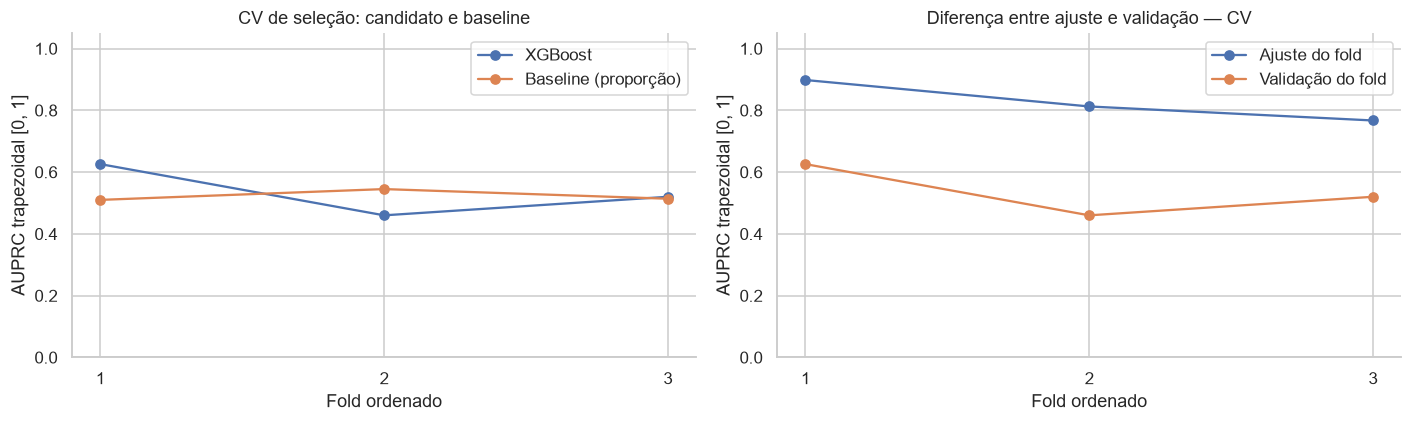

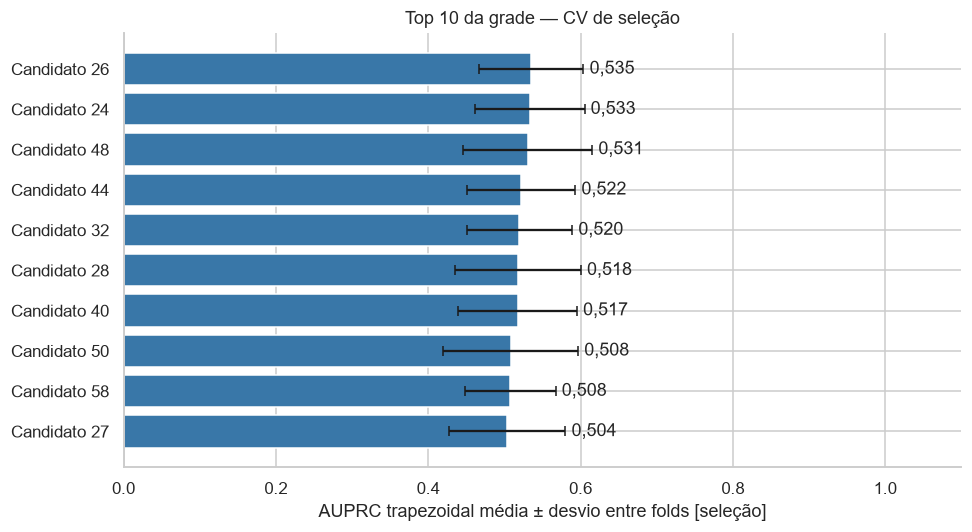

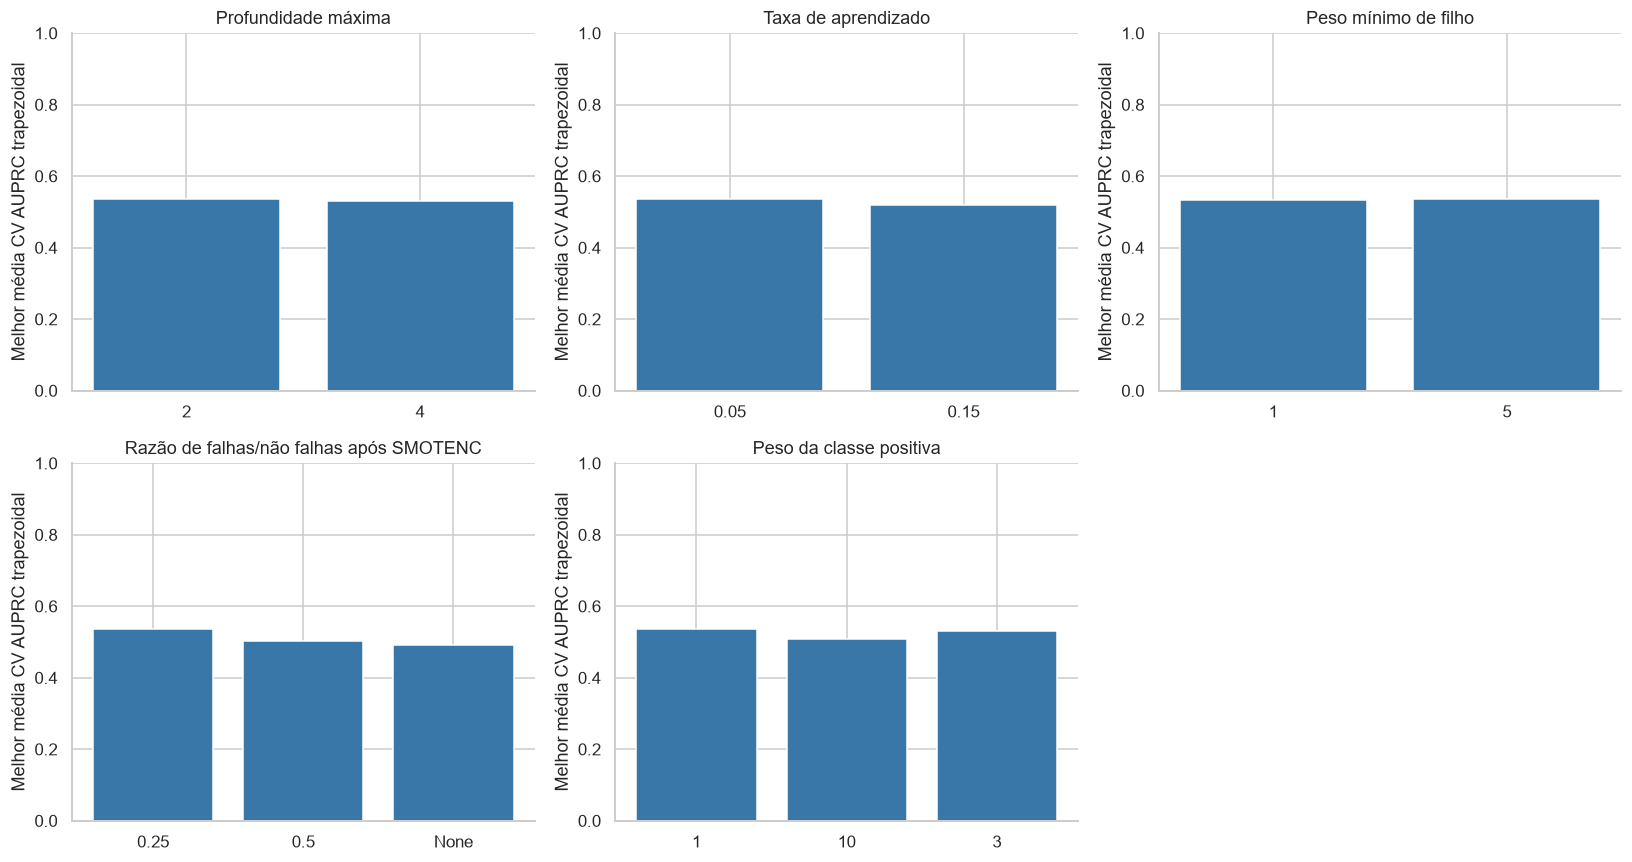

In [2]:
display(translated_markdown('**Grade condicional completa:**'))
for number, block in enumerate(manifest['search_grid'], start=1):
    display(translated_markdown(f'Bloco {number}'))
    display(readable_parameters(block))
print('Estratégia selecionada:', translate_text(manifest['balance_strategy']))
print('SMOTENC obrigatório no refit:', manifest['requires_smotenc'])
display(translated_markdown('**Parâmetros fixos:**'))
display(readable_parameters(manifest['fixed_params']))
display(translated_markdown('**Melhores parâmetros na grade:**'))
display(readable_parameters(manifest['best_params']))
print(f"AUPRC média de seleção: {manifest['best_cv_auprc']:.4f}")
print(f"Tempo da busca: {manifest['search_seconds']:.1f} s")
grid = report.table('grid_results')
selection_metric = manifest.get('selection_metric', 'ap')
columns = [f'rank_test_{selection_metric}', f'mean_test_{selection_metric}', f'std_test_{selection_metric}', f'mean_train_{selection_metric}', 'mean_test_ap', 'mean_test_auprc',
           'mean_test_f1', 'mean_test_recall', 'mean_test_precision', 'mean_fit_time', 'params']
display(readable_table(grid.sort_values(f'rank_test_{selection_metric}')[list(dict.fromkeys(columns))].head(10)))
report.cv_figures()

**Leitura dos perfis:** cada barra mostra o melhor AUPRC trapezoidal médio entre combinações
daquele valor, mantendo os demais parâmetros livres na grade. Não é efeito
isolado de hiperparâmetro. Os desvios do top 10 são dispersão entre folds,
não intervalos de confiança ou evidência de superioridade estatística.

## 3. Estatísticas por fold e baseline

`CV_SELECTION` refere-se ao candidato escolhido nas mesmas amostras usadas na
seleção, sem CV aninhada. Não são predições OOF nem resultado de teste.
O baseline Dummy usa a proporção observada no treino de cada fold.
Precision sem alertas é 0 no scorer da CV; nos diagnósticos de segmentos é indefinida (NaN).

In [3]:
folds = report.table('fold_metrics')
display(readable_table(folds))
display(readable_table(report.summary()))
selected_folds = folds.loc[folds.model.eq(MODEL_NAME)]
display(translated_markdown(f"**AUPRC de seleção:** {selected_folds.validation_auprc.mean():.3f} ± "
                f"{selected_folds.validation_auprc.std(ddof=1):.3f} (desvio amostral entre folds). "
                'Deslocamentos entre blocos e baixo suporte positivo limitam a interpretação.'))

,Receita,Fold ordenado,Origem,Observações de treino,Observações de validação,Falhas no treino,Falhas na validação,Limiar de alerta,AP (score) — treino,AP (score) — validação,ROC-AUC (score) — treino,ROC-AUC (score) — validação,F1 (%) — treino,F1 (%) — validação,Recall (%) — treino,Recall (%) — validação,Precision (%) — treino,Precision (%) — validação,Acurácia balanceada (%) — treino,Acurácia balanceada (%) — validação,AUPRC trapezoidal (score) — treino,AUPRC trapezoidal (score) — validação
0,XGBoost,1,CV de seleção,1.600,1.600,45,32,"0,5000","0,8986","0,6276","0,9725","0,9020","78,35%","45,36%","84,44%","68,75%","73,08%","33,85%","91,77%","83,00%","0,8981","0,6258"
1,Baseline (proporção),1,CV do baseline,1.600,1.600,45,32,"0,5000","0,0281","0,0200","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%","0,5141","0,5100"
2,XGBoost,2,CV de seleção,3.200,1.600,77,144,"0,5000","0,8131","0,4600","0,9798","0,8541","68,54%","42,21%","79,22%","29,17%","60,40%","76,36%","88,97%","64,14%","0,8125","0,4600"
3,Baseline (proporção),2,CV do baseline,3.200,1.600,77,144,"0,5000","0,0241","0,0900","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%","0,5120","0,5450"
4,XGBoost,3,CV de seleção,4.800,1.600,221,44,"0,5000","0,7681","0,5196","0,9766","0,9398","70,88%","33,18%","78,73%","79,55%","64,44%","20,96%","88,32%","85,53%","0,7671","0,5201"
5,Baseline (proporção),3,CV do baseline,4.800,1.600,221,44,"0,5000","0,0460","0,0275","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%","0,5230","0,5138"


**AUPRC de seleção:** 0,535 ± 0,084 (desvio amostral entre folds). Deslocamentos entre blocos e baixo suporte positivo limitam a interpretação.

## 4. FIT reajustado versus VALIDAÇÃO

`FIT_RESUBSTITUTION` é desempenho sobre o próprio ajuste, sujeito a sobreajuste.
`VALIDATION_TRAIN_BLOCK` é o bloco posterior fora da busca. Mesmos dados e limiar
para o candidato e o baseline. Nas tabelas e barras, F1/Recall/Precision e taxas aparecem em %, com vírgula decimal; AP e ROC-AUC permanecem scores em 0–1. Desvios de percentuais são pontos percentuais (p.p.). Os artefatos numéricos não são alterados.
`Não definido` nas barras indica ausência de alertas; a altura 0 é apenas convenção visual.

,Receita,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,XGBoost,Treino (reavaliação no ajuste),6.400,265,"4,14%","0,5000",5.981,154,58,207,"66,13%","78,11%","57,34%","97,49%","99,04%","2,51%","21,89%","5,64%","96,69%","87,80%","0,7506","0,7501","0,9739","0,0268","0,1095","0,6529","0,6444"
1,XGBoost,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.538,27,14,21,"50,60%","60,00%","43,75%","98,27%","99,10%","1,73%","40,00%","3,00%","97,44%","79,14%","0,5103","0,4917","0,9512","0,0213","0,0913","0,4997","0,4932"
2,Baseline (proporção),Treino (reavaliação no ajuste),6.400,265,"4,14%","0,5000",6.135,0,265,0,"0,00%","0,00%",Não definido,"100,00%","95,86%","0,00%","100,00%","0,00%","95,86%","50,00%","0,0414","0,5207","0,5000","0,0397","0,1724",0,0
3,Baseline (proporção),Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.565,0,35,0,"0,00%","0,00%",Não definido,"100,00%","97,81%","0,00%","100,00%","0,00%","97,81%","50,00%","0,0219","0,5109","0,5000","0,0218","0,1110",0,0


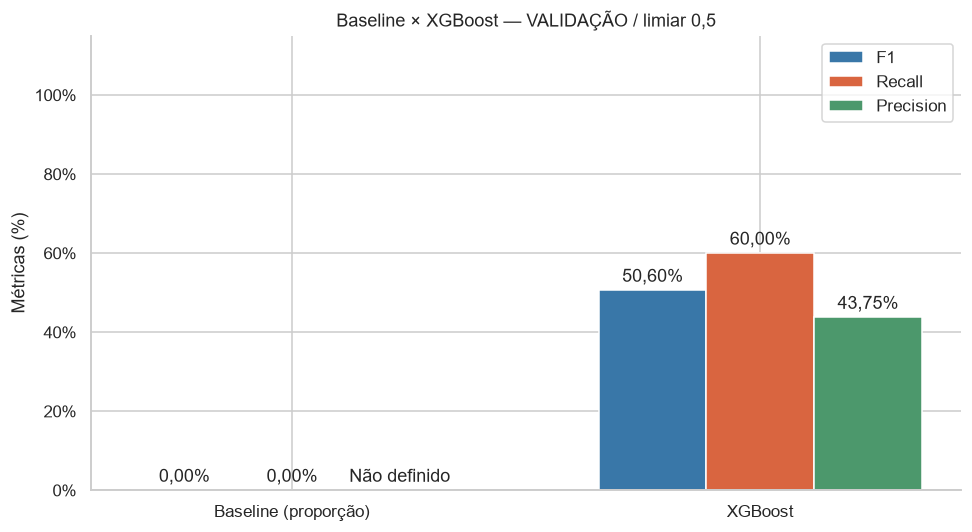

**Validação:** AUPRC=0,492; AP=0,510; F1=50,60%; Recall=60,00%; Precision=43,75%. Diferença de AP entre ajuste e validação = 0,240. São 35 falhas em 1600 observações. A diferença pode refletir sobreajuste e mudança entre blocos; não prova causalidade.

In [4]:
metrics = report.table('model_metrics')
display(readable_table(metrics))
report.comparison()
validation = metrics.loc[metrics.model.eq(MODEL_NAME) & metrics.origin.eq('VALIDATION_TRAIN_BLOCK')].iloc[0]
fit = metrics.loc[metrics.model.eq(MODEL_NAME) & metrics.origin.eq('FIT_RESUBSTITUTION')].iloc[0]
display(translated_markdown(f"**Validação:** AUPRC={validation.auprc:.3f}; AP={validation.ap:.3f}; F1={validation.f1:.2%}; "
    f"Recall={validation.recall:.2%}; Precision={validation.precision:.2%}. "
    f"Diferença de AP entre ajuste e validação = {fit.ap - validation.ap:.3f}. "
    f"São {int(validation.positives)} falhas em {int(validation.n)} observações. "
    'A diferença pode refletir sobreajuste e mudança entre blocos; não prova causalidade.'))

## 5. Matriz de confusão e relatório por classe

Eixo vertical real, horizontal previsto; classe positiva = falha. Matrizes em
contagens e normalizadas pela classe real. `zero_division=0` no relatório por classe.

,Classe / média,Precision (%),Recall (%),F1 (%),Observações da classe
0,Sem falha (0),"99,10%","98,27%","98,68%",1.565
1,Falha (1),"43,75%","60,00%","50,60%",35
2,Acurácia,"97,44%","97,44%","97,44%","0,9744"
3,Média macro,"71,42%","79,14%","74,64%",1.600
4,Média ponderada,"97,89%","97,44%","97,63%",1.600


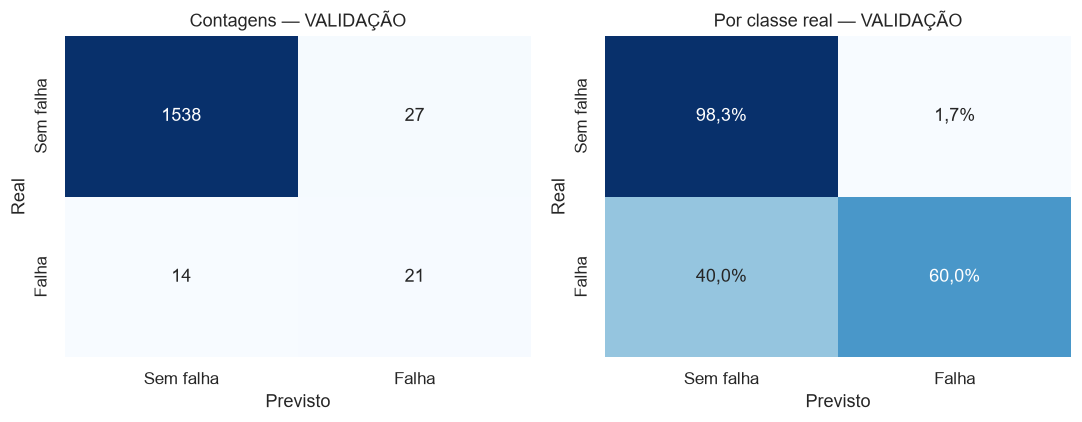

**Carga de revisão no bloco:** 48 alertas; 27 falsos positivos e 14 falhas perdidas. Custos e capacidade operacional ainda não foram informados.

In [5]:
display(readable_table(report.table('classification_report')))
report.confusion()
display(translated_markdown(f"**Carga de revisão no bloco:** {int(validation.tp + validation.fp)} alertas; "
                f"{int(validation.fp)} falsos positivos e {int(validation.fn)} falhas perdidas. "
                'Custos e capacidade operacional ainda não foram informados.'))

## 6. PR, ROC, confiabilidade e distribuição dos scores

AP e ROC usam scores positivos. A prevalência é a referência da PR. ROC complementa
a análise de classe rara. A curva de confiabilidade usa até 10 grupos por quantis;
não ajusta calibrador e não comprova calibração. Pesos de classe podem alterar os scores.

**Nota sobre AUPRC:** uma pontuação constante pode gerar poucos pontos na curva PR; a interpolação trapezoidal pode resultar em área alta mesmo com AP igual à prevalência. Por isso AP e AUPRC são mostradas separadamente, inclusive no baseline.

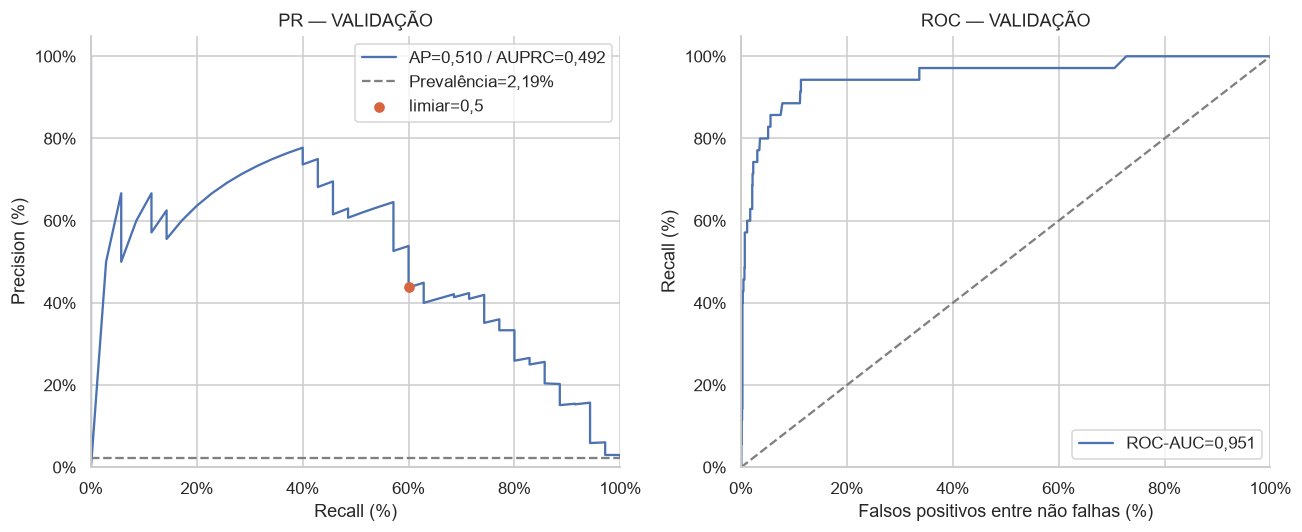

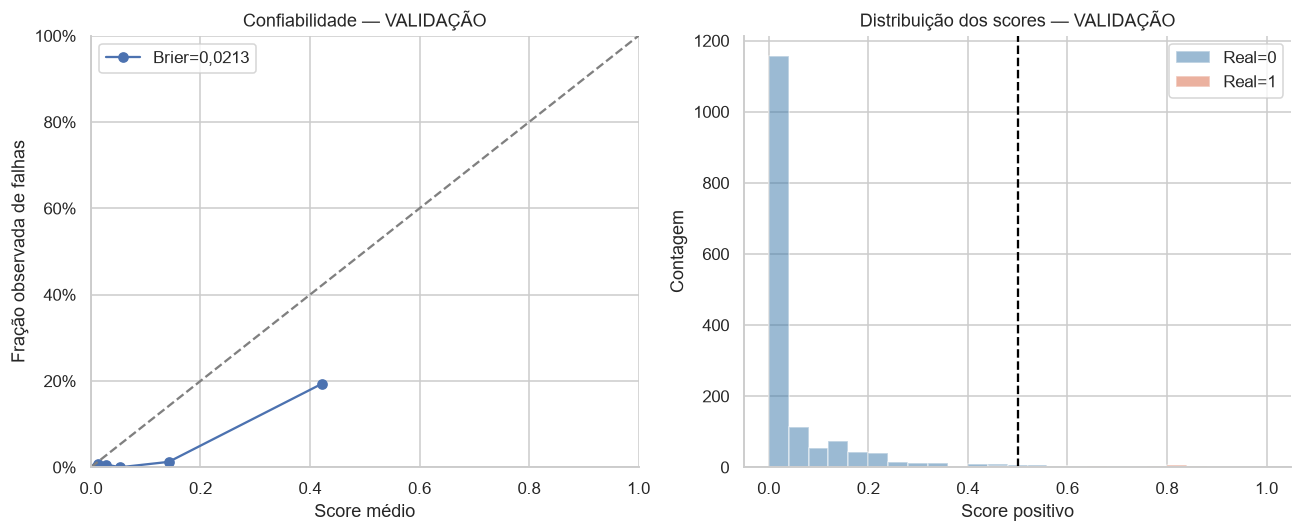

,Score médio,Taxa observada de falhas (%)
0,"0,0090","0,00%"
1,"0,0117","0,00%"
2,"0,0135","0,82%"
3,"0,0152","0,00%"
4,"0,0165","0,00%"
5,"0,0192","0,00%"
6,"0,0275","0,63%"
7,"0,0530","0,00%"
8,"0,1420","1,25%"
9,"0,4222","19,38%"


**Diagnóstico probabilístico:** Brier=0,0213; Log Loss=0,0913. Amostra com poucas falhas limita a estabilidade da curva de confiabilidade.

In [6]:
report.probability_figures()
display(readable_table(report.table('calibration')))
display(translated_markdown(f"**Diagnóstico probabilístico:** Brier={validation.brier:.4f}; "
                f"Log Loss={validation.log_loss:.4f}. "
                'Amostra com poucas falhas limita a estabilidade da curva de confiabilidade.'))

## 7. Sensibilidade ao threshold — sem tuning

O destaque mostra a referência 0,5. Varrer limiares na validação é **diagnóstico**,
sem mudar o pacote ou declarar um ótimo. Recall/Precision/F1 mudam; AP dos mesmos
scores não muda. Uma escolha operacional futura exige objetivo e validação própria.

,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Validação (somente diagnóstico),1.600,35,"2,19%","0,0500",1.197,368,2,33,"15,14%","94,29%","8,23%","76,49%","99,83%","23,51%","5,71%","25,06%","76,88%","85,39%","0,5103","0,4917","0,9512","0,0213","0,0913","0,2389","0,1158"
1,Validação (somente diagnóstico),1.600,35,"2,19%","0,1000",1.283,282,2,33,"18,86%","94,29%","10,48%","81,98%","99,84%","18,02%","5,71%","19,69%","82,25%","88,13%","0,5103","0,4917","0,9512","0,0213","0,0913","0,2806","0,1553"
2,Validação (somente diagnóstico),1.600,35,"2,19%","0,2000",1.438,127,4,31,"32,12%","88,57%","19,62%","91,88%","99,72%","8,12%","11,43%","9,88%","91,81%","90,23%","0,5103","0,4917","0,9512","0,0213","0,0913","0,3945","0,2960"
3,Validação (somente diagnóstico),1.600,35,"2,19%","0,3000",1.501,64,7,28,"44,09%","80,00%","30,43%","95,91%","99,54%","4,09%","20,00%","5,75%","95,56%","87,96%","0,5103","0,4917","0,9512","0,0213","0,0913","0,4770","0,4226"
4,Validação (somente diagnóstico),1.600,35,"2,19%","0,4000",1.517,48,9,26,"47,71%","74,29%","35,14%","96,93%","99,41%","3,07%","25,71%","4,62%","96,44%","85,61%","0,5103","0,4917","0,9512","0,0213","0,0913","0,4960","0,4611"
5,Validação (somente diagnóstico),1.600,35,"2,19%","0,5000",1.538,27,14,21,"50,60%","60,00%","43,75%","98,27%","99,10%","1,73%","40,00%","3,00%","97,44%","79,14%","0,5103","0,4917","0,9512","0,0213","0,0913","0,4997","0,4932"
6,Validação (somente diagnóstico),1.600,35,"2,19%","0,6000",1.550,15,15,20,"57,14%","57,14%","57,14%","99,04%","99,04%","0,96%","42,86%","2,19%","98,12%","78,09%","0,5103","0,4917","0,9512","0,0213","0,0913","0,5618","0,5618"
7,Validação (somente diagnóstico),1.600,35,"2,19%","0,7000",1.558,7,19,16,"55,17%","45,71%","69,57%","99,55%","98,80%","0,45%","54,29%","1,44%","98,38%","72,63%","0,5103","0,4917","0,9512","0,0213","0,0913","0,5563","0,5438"
8,Validação (somente diagnóstico),1.600,35,"2,19%","0,8000",1.561,4,25,10,"40,82%","28,57%","71,43%","99,74%","98,42%","0,26%","71,43%","0,88%","98,19%","64,16%","0,5103","0,4917","0,9512","0,0213","0,0913","0,4447","0,4007"
9,Validação (somente diagnóstico),1.600,35,"2,19%","0,9000",1.563,2,33,2,"10,26%","5,71%","50,00%","99,87%","97,93%","0,13%","94,29%","0,25%","97,81%","52,79%","0,5103","0,4917","0,9512","0,0213","0,0913","0,1636","0,0985"


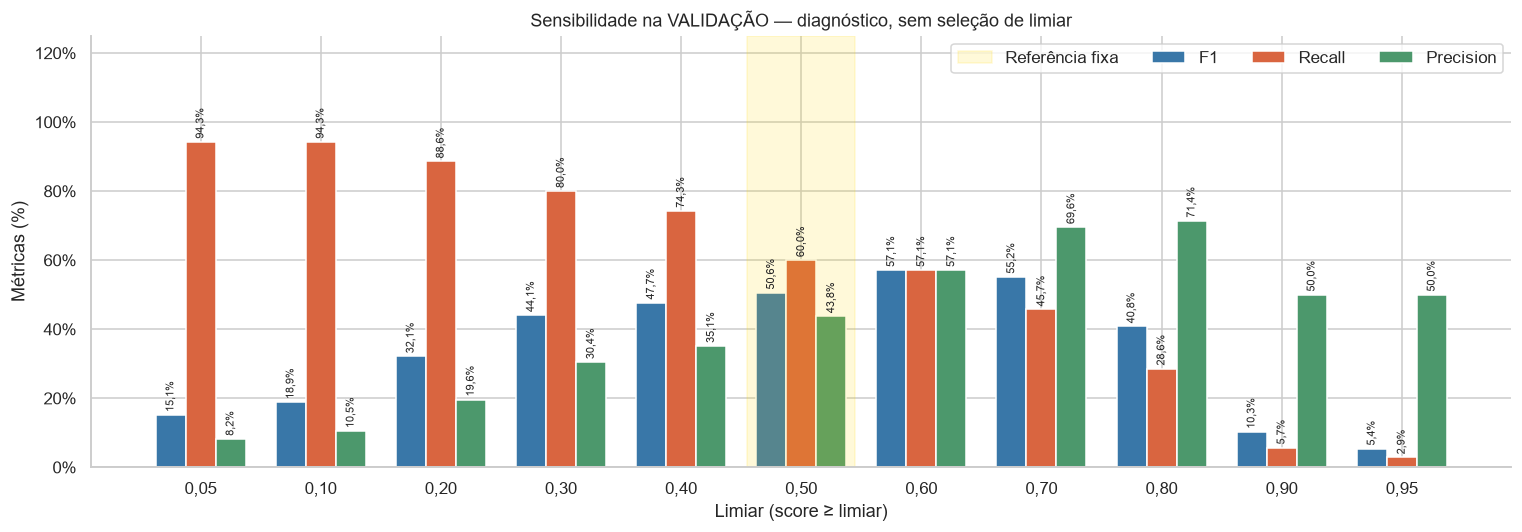

In [7]:
display(readable_table(report.table('threshold_diagnostics')))
report.threshold_figure()

## 8. Associação versus importância preditiva

Associação calculada em FIT: Spearman para sensores, Cramér V para Type (magnitude
com medidas distintas, não equivalentes). Importância por permutação no bloco de
validação, agregada por entrada original passando pelo pipeline completo.
A unidade é queda de AUPRC trapezoidal; as barras de erro são desvio das permutações, não confiança.
Correlação entre sensores pode repartir importâncias. Nada foi removido com esse diagnóstico.

,Variável,Pearson com falha — treino,Spearman com falha — treino,Magnitude da associação — treino,Medida de associação,Queda de AP por permutação — validação,Queda de AUPRC por permutação — validação,Desvio da permutação de AUPRC (score),Desvio da permutação (score)
0,Temperatura do ar [K],"0,0861","0,0897","0,0897",Módulo de Spearman,"-0,0152","-0,0160","0,0117","0,0110"
1,Temperatura do processo [K],"0,0439","0,0500","0,0500",Módulo de Spearman,"-0,0273","-0,0285","0,0201","0,0188"
2,Velocidade de rotação [rpm],"-0,0580","-0,1982","0,1982",Módulo de Spearman,"0,0610","0,0516","0,0263","0,0259"
3,Torque [Nm],"0,2110","0,1950","0,1950",Módulo de Spearman,"0,3874","0,3776","0,0243","0,0246"
4,Desgaste da ferramenta [min],"0,0925","0,0885","0,0885",Módulo de Spearman,"0,2412","0,2361","0,0440","0,0434"
5,Tipo,Não definido,Não definido,"0,0318",V de Cramér,"-0,0027","-0,0027","0,0020","0,0020"


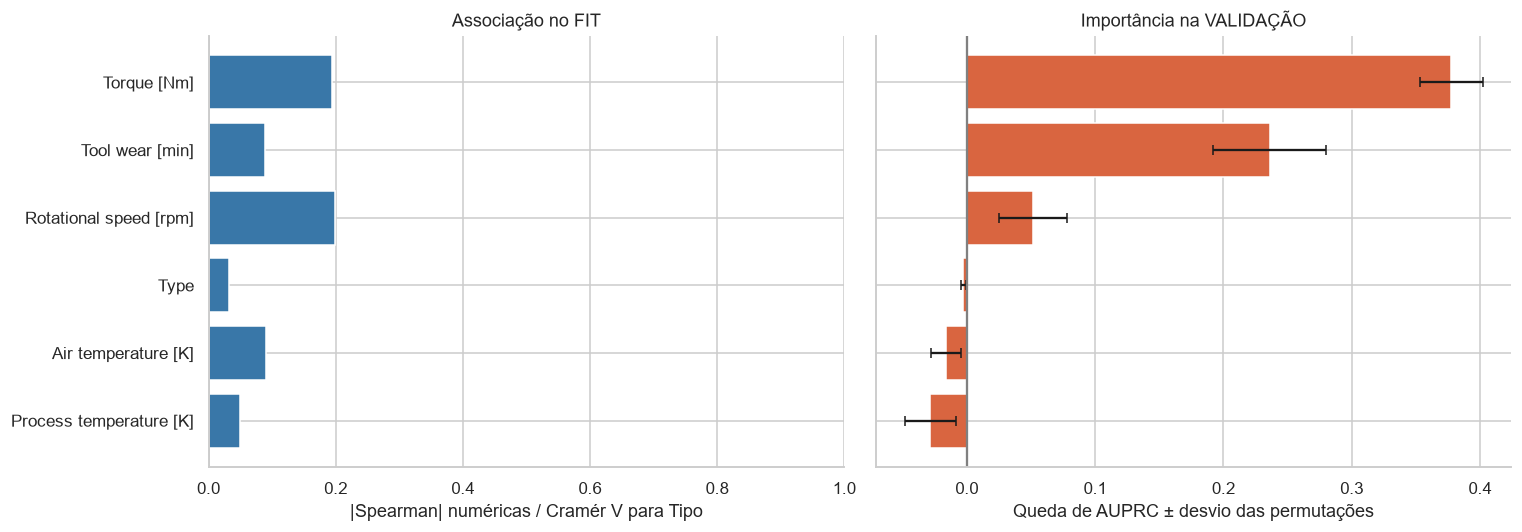

In [8]:
display(readable_table(report.table('feature_association_importance')))
report.feature_figure()

## 9. Diagnóstico por tamanho do prefixo

Parâmetros congelados da busca, prefixos ordenados e a mesma validação. Prefixos
de tamanhos distintos abrangem regimes diferentes: **não é uma learning curve i.i.d.
controlada**. É diagnóstico descritivo; não escolhe novamente os parâmetros.

,Observações de treino,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,1.600,Treino (prefixo),1.600,45,"2,81%","0,5000",1.541,14,7,38,"78,35%","84,44%","73,08%","99,10%","99,55%","0,90%","15,56%","3,25%","98,69%","91,77%","0,8986","0,8981","0,9725","0,0111","0,0512","0,7789","0,7768"
1,1.600,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.518,47,9,26,"48,15%","74,29%","35,62%","97,00%","99,41%","3,00%","25,71%","4,56%","96,50%","85,64%","0,5804","0,5770","0,9629","0,0230","0,0838","0,4997","0,4657"
2,3.200,Treino (prefixo),3.200,77,"2,41%","0,5000",3.083,40,16,61,"68,54%","79,22%","60,40%","98,72%","99,48%","1,28%","20,78%","3,16%","98,25%","88,97%","0,8131","0,8125","0,9798","0,0170","0,0705","0,6832","0,6766"
3,3.200,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.532,33,7,28,"58,33%","80,00%","45,90%","97,89%","99,55%","2,11%","20,00%","3,81%","97,50%","88,95%","0,6804","0,6714","0,9719","0,0193","0,0754","0,5950","0,5714"
4,4.800,Treino (prefixo),4.800,221,"4,60%","0,5000",4.483,96,47,174,"70,88%","78,73%","64,44%","97,90%","98,96%","2,10%","21,27%","5,62%","97,02%","88,32%","0,7681","0,7671","0,9766","0,0248","0,1018","0,6971","0,6932"
5,4.800,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.539,26,11,24,"56,47%","68,57%","48,00%","98,34%","99,29%","1,66%","31,43%","3,12%","97,69%","83,46%","0,5819","0,5646","0,9571","0,0209","0,0895","0,5625","0,5532"
6,6.400,Treino (prefixo),6.400,265,"4,14%","0,5000",5.981,154,58,207,"66,13%","78,11%","57,34%","97,49%","99,04%","2,51%","21,89%","5,64%","96,69%","87,80%","0,7506","0,7501","0,9739","0,0268","0,1095","0,6529","0,6444"
7,6.400,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.538,27,14,21,"50,60%","60,00%","43,75%","98,27%","99,10%","1,73%","40,00%","3,00%","97,44%","79,14%","0,5103","0,4917","0,9512","0,0213","0,0913","0,4997","0,4932"


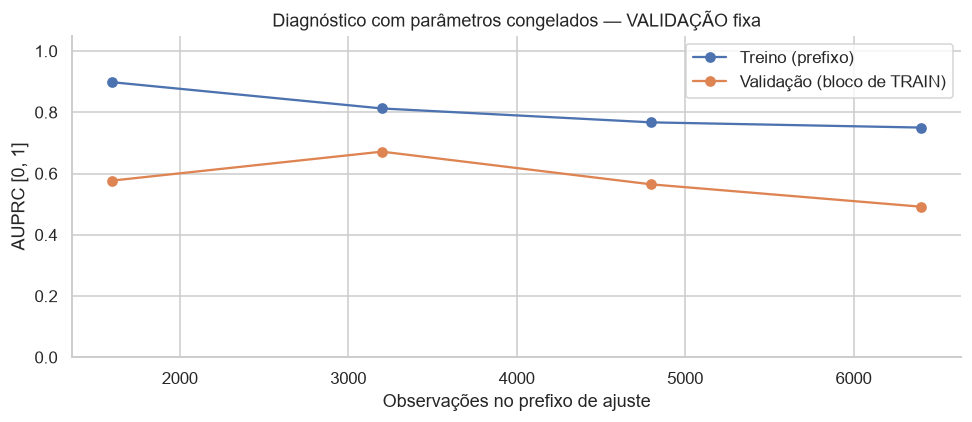

In [9]:
display(readable_table(report.table('learning_diagnostic')))
report.learning_figure()

## 10. Erros por segmento e ordem dos registros

Contagens, taxas reais, TP/FP/FN/TN e métricas por Type e faixas de sensores.
Limites das faixas aprendidos apenas em FIT; extremos cobrem valores futuros.
NaN indica denominador inexistente. Não somar suportes de features diferentes:
as mesmas observações aparecem em cada análise. UDI não representa tempo decorrido.

,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Tipo,H,147,1,"0,68%","0,5000",144,2,1,0,"0,00%","0,00%","0,00%","98,63%","99,31%","1,37%","100,00%","1,36%","97,96%","49,32%","0,3333","0,1667","0,9863","0,0123","0,0607","-0,0097","-0,0092"
1,Tipo,L,968,24,"2,48%","0,5000",928,16,10,14,"51,85%","58,33%","46,67%","98,31%","98,93%","1,69%","41,67%","3,10%","97,31%","78,32%","0,5193","0,4941","0,9401","0,0216","0,0930","0,5082","0,5049"
2,Tipo,M,485,10,"2,06%","0,5000",466,9,3,7,"53,85%","70,00%","43,75%","98,11%","99,36%","1,89%","30,00%","3,30%","97,53%","84,05%","0,5846","0,5602","0,9738","0,0235","0,0971","0,5419","0,5264"


,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Temperatura do ar [K],"(298.1, 299.6]",33,0,"0,00%","0,5000",33,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,Não definido,"0,0112","0,0637",Não definido,Não definido
1,Temperatura do ar [K],"(299.6, 301.3]",1.359,30,"2,21%","0,5000",1.308,21,13,17,"50,00%","56,67%","44,74%","98,42%","99,02%","1,58%","43,33%","2,80%","97,50%","77,54%","0,5278","0,5074","0,9496","0,0202","0,0879","0,4909","0,4874"
2,Temperatura do ar [K],"(301.3, 302.4]",208,5,"2,40%","0,5000",197,6,1,4,"53,33%","80,00%","40,00%","97,04%","99,49%","2,96%","20,00%","4,81%","96,63%","88,52%","0,4600","0,3900","0,9724","0,0302","0,1176","0,5516","0,5179"
3,Temperatura do processo [K],"(309.4, 310.5]",521,9,"1,73%","0,5000",500,12,3,6,"44,44%","66,67%","33,33%","97,66%","99,40%","2,34%","33,33%","3,45%","97,12%","82,16%","0,4689","0,4161","0,8789","0,0251","0,1062","0,4589","0,4313"
4,Temperatura do processo [K],"(310.5, 311.3]",544,12,"2,21%","0,5000",523,9,3,9,"60,00%","75,00%","50,00%","98,31%","99,43%","1,69%","25,00%","3,31%","97,79%","86,65%","0,6594","0,6374","0,9881","0,0185","0,0825","0,6020","0,5891"
5,Temperatura do processo [K],"(311.3, inf]",535,14,"2,62%","0,5000",515,6,8,6,"46,15%","42,86%","50,00%","98,85%","98,47%","1,15%","57,14%","2,24%","97,38%","70,85%","0,5643","0,5482","0,9577","0,0205","0,0857","0,4496","0,4482"
6,Velocidade de rotação [rpm],"(-inf, 1406.0]",334,21,"6,29%","0,5000",290,23,5,16,"53,33%","76,19%","41,03%","92,65%","98,31%","7,35%","23,81%","11,68%","91,62%","84,42%","0,6787","0,6689","0,9665","0,0637","0,2411","0,5203","0,4918"
7,Velocidade de rotação [rpm],"(1406.0, 1469.0]",293,4,"1,37%","0,5000",287,2,3,1,"28,57%","25,00%","33,33%","99,31%","98,97%","0,69%","75,00%","1,02%","98,29%","62,15%","0,4399","0,4102","0,8737","0,0142","0,0715","0,2802","0,2773"
8,Velocidade de rotação [rpm],"(1469.0, 1542.0]",364,1,"0,27%","0,5000",363,0,1,0,"0,00%","0,00%",Não definido,"100,00%","99,73%","0,00%","100,00%","0,00%","99,73%","50,00%","0,0769","0,0385","0,9669","0,0040","0,0297",0,0
9,Velocidade de rotação [rpm],"(1542.0, 1643.0]",281,0,"0,00%","0,5000",281,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,Não definido,"0,0022","0,0248",Não definido,Não definido


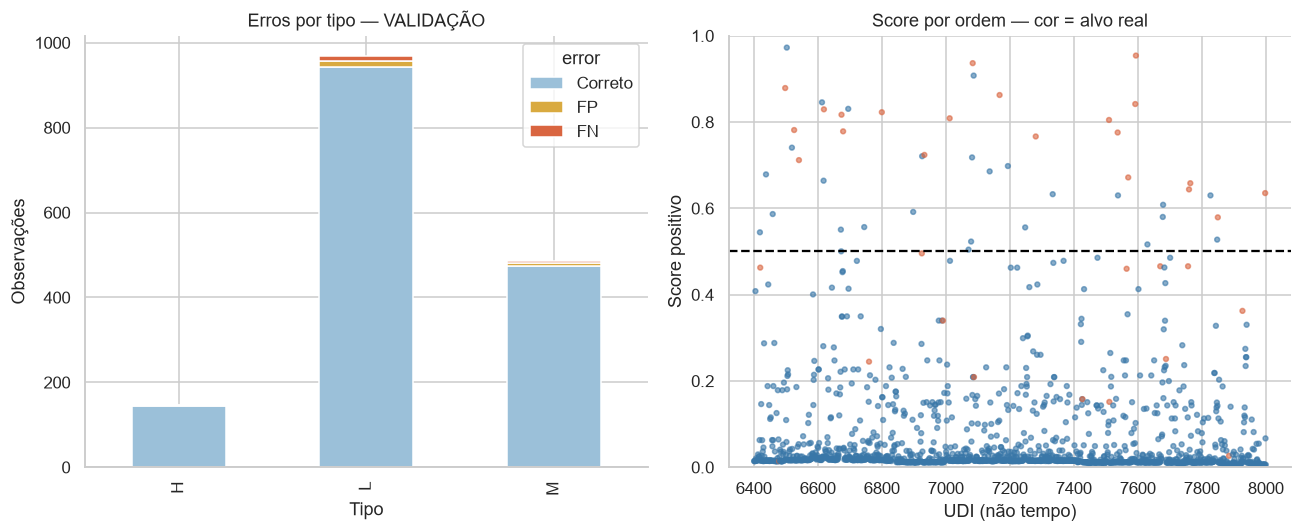

In [10]:
display(readable_table(report.table('segment_type')))
display(readable_table(report.table('segment_numeric')))
report.error_figure()

## 11. Artefato, reprodutibilidade e limites

O pipeline local corresponde ao refit em FIT (6.400), não a um modelo reajustado
nas 8.000 observações ou selecionado como vencedor do projeto. Não existe avaliação TEST.
O binário é local e ignorado no Git; carregar somente artefatos de origem confiável.

In [11]:
print('Pipeline:', manifest['model_path'])
print('SHA256:', manifest['model_sha256'])
print('Equivalência após serialização:', manifest['serialization_verified'])
print('Política de limiar:', manifest['threshold_policy'])
print('Figuras:', report.figures.relative_to(ROOT))
print('Tabelas:', report.tables.relative_to(ROOT))
display(manifest['limitations'])
display(translated_markdown('**Próxima decisão:** comparar os dois candidatos sob este mesmo protocolo, '
    'considerando AP, falhas perdidas, falsos alarmes, estabilidade e custo. '
    'Não ajustar features ou threshold com TEST. Nenhum vencedor de produção foi declarado.'))

Pipeline: models/train_xgboost_20261031T235601Z_fa7abc82/pipeline.joblib
SHA256: 34e76db9830f13bc55b29c324ab1e9319361da02809b565aafa670d6455e6e2d
Equivalência após serialização: True
Política de limiar: fixed reference; not tuned
Figuras: reports\figures\train_xgboost_20261031T235601Z_fa7abc82
Tabelas: reports\metrics\train_xgboost_20261031T235601Z_fa7abc82


['UDI is record order, not verified time',
 'no gap or physical machine ID',
 'CV winner scores are selection-optimistic',
 'validation belongs to EDA-explored TRAIN',
 'probability calibration not demonstrated',
 'no final TEST evaluation']

**Próxima decisão:** comparar os dois candidatos sob este mesmo protocolo, considerando AP, falhas perdidas, falsos alarmes, estabilidade e custo. Não ajustar features ou limiar com TEST. Nenhum vencedor de produção foi declarado.

## 12. Comparação com a execução anterior

Mesmos registros e folds. AUPRC trapezoidal e AP são calculadas com predict_proba[:, 1]; a execução anterior já usava predict_proba. Comparação na validação de desenvolvimento reutilizada; não demonstra generalização independente. O efeito conjunto de sampler, pesos e critério de busca não pode ser atribuído somente ao SMOTENC. TEST permanece reservado.

,Versão,Limiar de alerta,AUPRC trapezoidal (score),AP (score),F1 (%),Recall (%),Precision (%),FP: falsos alertas,FN: falhas não detectadas
0,Anterior,"0,5000","0,4917","0,5103","50,60%","60,00%","43,75%",27,14
1,Atual,"0,5000","0,4917","0,5103","50,60%","60,00%","43,75%",27,14


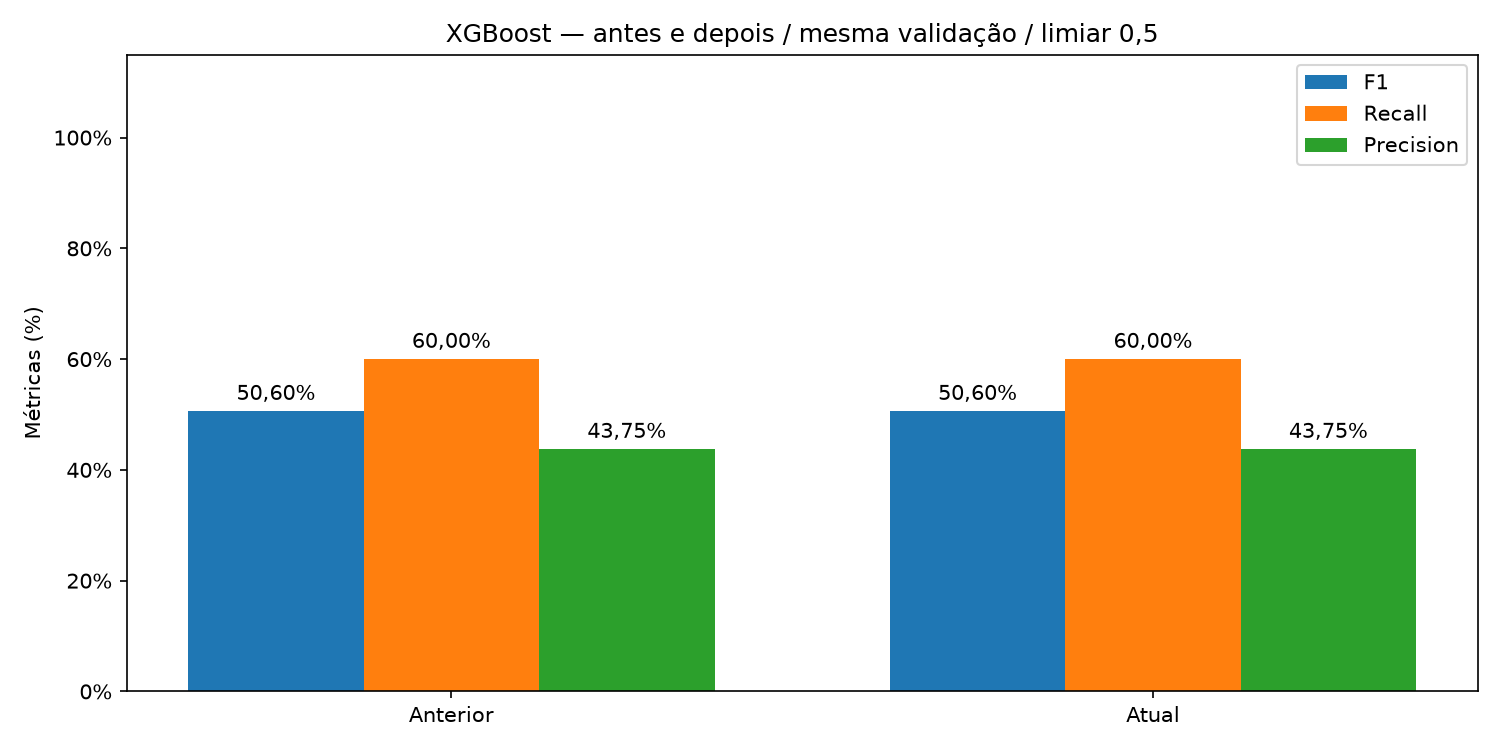

AUPRC: 0,4917 → 0,4917; AP: 0,5103 → 0,5103; F1: 50,60% → 50,60%. Não houve ajuste de limiar nesta comparação.

In [12]:
comparison = report.table('previous_comparison')
display(readable_table(comparison[['version', 'threshold', 'auprc', 'ap', 'f1', 'recall', 'precision', 'fp', 'fn']]))
from IPython.display import Image
display(Image(filename=str(report.figures / 'previous_comparison.png')))
before, after = comparison.iloc[0], comparison.iloc[1]
display(translated_markdown(f'AUPRC: {before.auprc:.4f} → {after.auprc:.4f}; ' f'AP: {before.ap:.4f} → {after.ap:.4f}; ' f'F1: {before.f1:.2%} → {after.f1:.2%}. ' 'Não houve ajuste de limiar nesta comparação.'))

## 13. Auditoria do SMOTENC

Contagens reais do sampler escolhido em cada treino e no refit. As contagens de CV são uma reprodução apenas do sampler com os parâmetros escolhidos; não acrescentam ajuste de classificador. Nenhum registro de validação foi reamostrado. As razões são minoria/maioria, não proporção da minoria no total. Não há undersampling.

In [13]:
display(readable_table(report.table('sampling_counts')))

,Origem,Não falhas antes do sampler,Falhas antes do sampler,Não falhas após sampler,Falhas após sampler,Falhas sintéticas criadas
0,CV_FIT_1,1.555,45,1.555,388,343
1,CV_FIT_2,3.123,77,3.123,780,703
2,CV_FIT_3,4.579,221,4.579,1.144,923
3,REFIT,6.135,265,6.135,1.533,1.268


## 14. Estratégias de balanceamento — decisão na CV

Melhor configuração de cada braço segundo AUPRC trapezoidal, com dispersão entre folds.
Somente candidatos com SMOTENC são elegíveis para refit, conforme o requisito.
Os controles podem ter score maior; isso será mostrado, sem ocultar ou chamá-los de escolhidos.
As tabelas desta seção são de CV de seleção, não do bloco de validação.
O verde destaca a escolha; cinza identifica controles. Não há confirmação estatística independente.

,strategy,Elegível para refit?,Selecionada?,Índice do candidato,AUPRC trapezoidal (score) — média — validação CV,AUPRC trapezoidal (score) — desvio — validação CV,F1 (%) — média — validação CV,Recall (%) — média — validação CV,Precision (%) — média — validação CV,Parâmetros
1,SMOTENC,Sim,Sim,26,"0,5353","0,0686","40,25%","59,15%","43,72%","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 5, ""model__scale_pos_weight"": 1, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
2,SMOTENC + pesos,Sim,Não,48,"0,5305","0,0849","38,33%","60,44%","42,14%","{""model__learning_rate"": 0.05, ""model__max_depth"": 4, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 3, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
3,Só pesos (controle),Não,Não,13,"0,4926","0,0706","38,03%","52,56%","45,13%","{""model__learning_rate"": 0.05, ""model__max_depth"": 4, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 10, ""sampler"": ""passthrough""}"
0,Sem balanceamento (controle),Não,Não,0,"0,4908","0,0751","33,93%","33,69%","63,47%","{""model__learning_rate"": 0.05, ""model__max_depth"": 2, ""model__min_child_weight"": 1, ""model__scale_pos_weight"": 1, ""sampler"": ""passthrough""}"


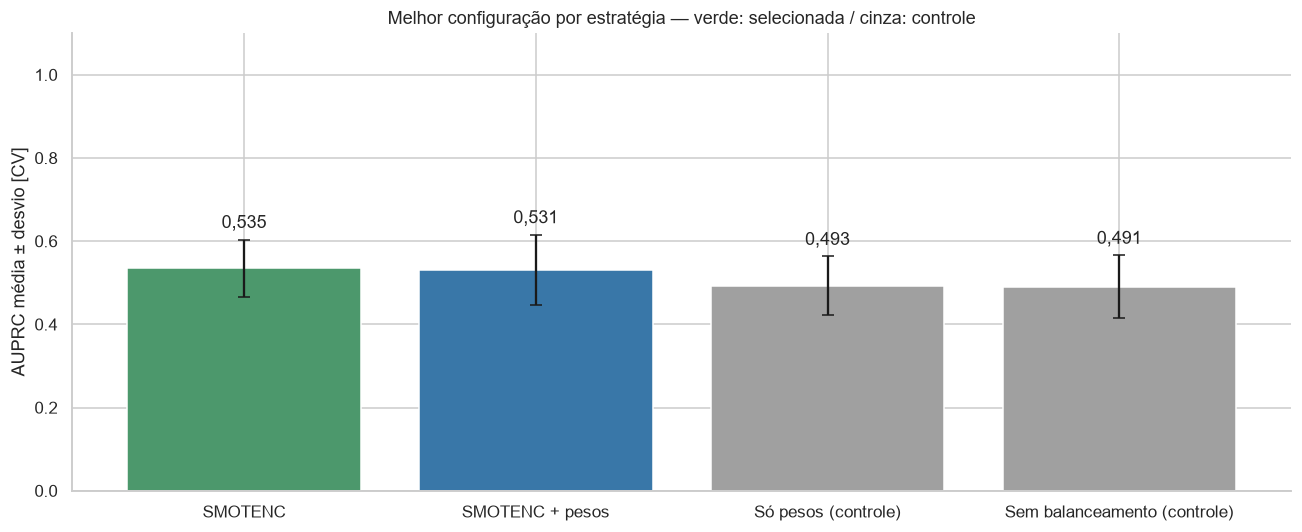

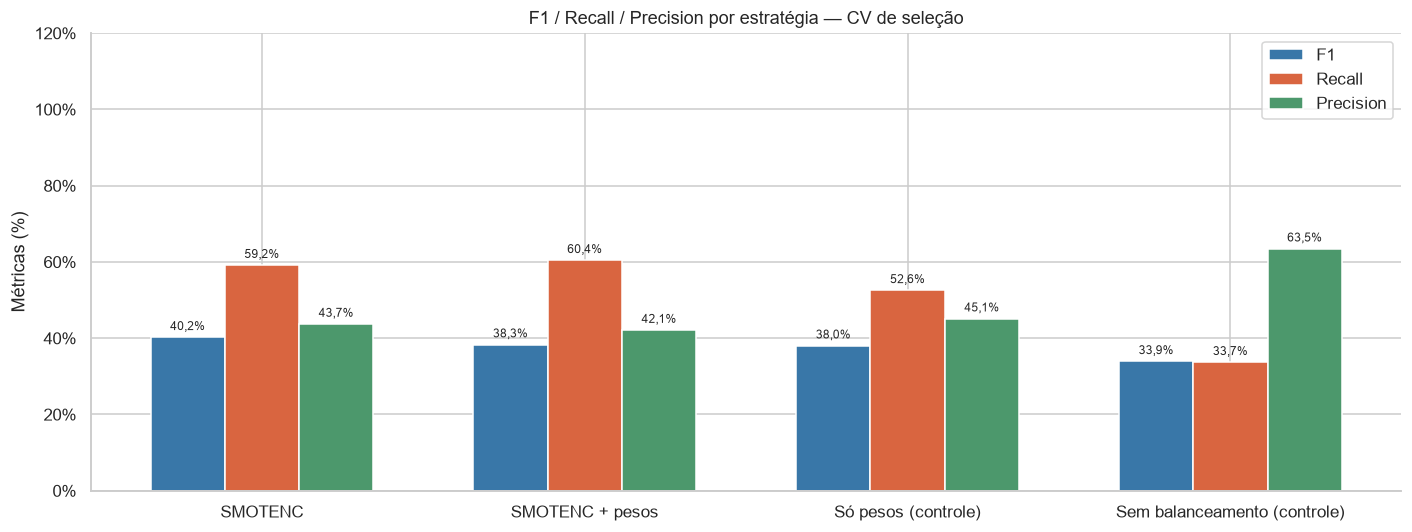

Melhor índice irrestrito: 26; selecionado com SMOTENC: 26. A escolha usa CV, nunca as métricas do bloco de validação.

In [14]:
strategies = report.table('strategy_cv_summary')
metric = report.selection_metric
columns = ['strategy', 'eligible_for_refit', 'selected', 'candidate_index', f'mean_test_{metric}', f'std_test_{metric}', 'mean_test_f1', 'mean_test_recall', 'mean_test_precision', 'params']
display(readable_table(strategies.sort_values(f'mean_test_{metric}', ascending=False)[columns]))
report.strategy_figures()
overall = int(manifest['global_best_candidate_index'])
selected = int(manifest['best_candidate_index'])
display(translated_markdown(f'Melhor índice irrestrito: {overall}; selecionado com SMOTENC: {selected}. ' 'A escolha usa CV, nunca as métricas do bloco de validação.'))